# Container loading

A wholesaler of kitchenware ships cartons every afternoon. The cartons go onto pallets in the
warehouse, the pallets and loose parcels go into a van that makes several stops, and small web orders
leave in shipping cartons picked from a short catalog. All three are the same question in three
dimensions: **where does every box stand, so that it fits, nothing is crushed, and as little space
as possible is paid for**.

In this notebook you will:

1. describe boxes and pallets as Python objects,
2. solve the load and draw every pallet with its boxes,
3. check the result yourself, without trusting the solver's score,
4. reweigh a rule and see what it was costing,
5. load a van so that every stop finds its parcels at the door,
6. pick the cheapest shipping cartons for an order,
7. add late boxes to a plan that is already made.

Requires Python 3.11+ and optimaru 0.9.0 or later: `pip install "optimaru>=0.9.0" matplotlib`

In [1]:
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Patch
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

from optimaru import container_loading as cl
from optimaru.container_loading import constraints as rules
from optimaru.container_loading.models import ContainerLoadingProblemModel

COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, MUTED = "#52514e", "#898781"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK, "axes.titlesize": 12,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "xtick.color": MUTED, "ytick.color": MUTED,
    "grid.color": "#e1e0d9", "grid.linewidth": 0.8, "legend.frameon": False, "font.size": 10,
})

## 1. Describe the load

Three objects describe the problem. Lengths and weights are whole numbers in any unit you like; this
notebook uses millimetres and grams.

| Object | What it holds |
| --- | --- |
| `Container` | one space: `length`, `width`, `height`, an optional `max_weight`, and a `cost` (1 by default) |
| `Item` | one box: its size and `weight`, which `rotations` are allowed, and the optional `max_load_on_top`, `unload_order` and `group` |
| `ContainerLoadingProblem` | the `containers`, the `items`, and `min_support_ratio`: how much of a box's base must rest on something (0.8) |

`x` runs along a container's length, from the closed end to the door; `y` across; `z` up. A box with
`rotations=cl.Rotation.UPRIGHT` keeps its height vertical, `FIXED` goes in as given, and the default
`ALL` may lie on any face.

Here is a fictional afternoon: 46 cartons of five kinds for euro pallets of 1200 x 800 mm, loaded up
to 1500 mm, that carry 500 kg each. The glassware cartons carry at most 6 kg on top. The cartons go
to three shops, and a shop would rather get its cartons on one pallet: that is the `group`.

In [2]:
#          name         length width height weight(g) rotations             carries(g)
KINDS = [("stock pot",     600,  400,  400,  14000, cl.Rotation.UPRIGHT, None),
         ("pan set",       600,  400,  200,   9000, cl.Rotation.ALL,     None),
         ("cutlery",       400,  300,  200,   7000, cl.Rotation.ALL,     None),
         ("glassware",     400,  300,  300,   5000, cl.Rotation.UPRIGHT, 6000),
         ("utensils",      300,  200,  200,   2500, cl.Rotation.ALL,     None)]
KIND_COLOR = {kind[0]: COLORS[i] for i, kind in enumerate(KINDS)}
COUNTS = [8, 10, 10, 8, 10]


def make_problem(pallets=4):
    """A fresh, unsolved load. Solvers work in place, so each experiment gets its own."""
    items = []
    for (name, length, width, height, weight, rotations, carries), count in zip(KINDS, COUNTS):
        for i in range(count):
            items.append(cl.Item(f"{name} {i + 1}", length, width, height, weight=weight, rotations=rotations,
                                 max_load_on_top=carries, group=f"shop {len(items) % 3 + 1}"))
    containers = [cl.Container(f"pallet {p + 1}", 1200, 800, 1500, max_weight=500_000) for p in range(pallets)]
    return cl.ContainerLoadingProblem(containers, items)


def kind_of(item):
    return item.id.rsplit(" ", 1)[0]


problem = make_problem()
volume = sum(item.length * item.width * item.height for item in problem.items)
pallet = problem.containers[0]
pallet_volume = pallet.length * pallet.width * pallet.height
print(f"{len(problem.items)} cartons, {volume / 1e9:.2f} m3 and {sum(i.weight for i in problem.items) / 1000:.0f} kg in all")
print(f"one pallet holds {pallet_volume / 1e9:.2f} m3 and {pallet.max_weight / 1000:.0f} kg")
print("so the volume alone needs at least", int(np.ceil(volume / pallet_volume)), "pallets")
print("cartons per shop:", dict(sorted(Counter(item.group for item in problem.items).items())))

46 cartons, 1.90 m3 and 337 kg in all
one pallet holds 1.44 m3 and 500 kg
so the volume alone needs at least 2 pallets
cartons per shop: {'shop 1': 16, 'shop 2': 15, 'shop 3': 15}


## 2. Solve it

`cl.solve` fills in the problem and returns it. It runs on the compiled C++ engine, like every use
case. What it searches is not coordinates but an **order**: every container has a loading order, and
a placement rule puts the boxes down one after the other, each at the first free corner that takes
it, from the closed end towards the door, then up, then across. A box must be inside the walls, clear
of the other boxes, and have enough of its base supported. The search moves boxes between the orders
and inside them; where they stand follows.

The score has two levels, compared in order:

- **hard**: minus what is broken: boxes that found no place, weight above a pallet's limit, weight
  on a box above what it carries, and (section 5) boxes in the way of an earlier stop. `0` means the
  plan is feasible.
- **soft**: minus the cost of the containers in use (their number, while every `cost` is 1) and, for
  every group, the containers it is spread over beyond the first.

The search stops at `time_limit_seconds`, 30 by default, so set it.

In [3]:
score = cl.solve(problem, time_limit_seconds=5, random_seed=1).score

def shops_split(problem):
    """Over the shops, the pallets a shop's cartons are on beyond the first."""
    return int(cl.constraint_costs(problem)["group_split_cost"]["costs"][0])


print("score            :", score.hard, "/", score.soft)
print("pallets used     :", problem.containers_used())
print("shops split      :", shops_split(problem))
print("boxes not placed :", problem.unplaced_items())
for container in problem.containers:
    if container.placed_items:
        shops = sorted({problem.items[i].group for i in container.placed_items})
        print(f"{container.id}: {len(container.placed_items):2d} boxes, {container.loaded_weight / 1000:5.1f} kg, "
              f"{container.fill_ratio:.0%} of the volume, {', '.join(shops)}")

score            : 0 / -2.0
pallets used     : 2
shops split      : 0
boxes not placed : []
pallet 1: 31 boxes, 229.5 kg, 90% of the volume, shop 1, shop 2
pallet 4: 15 boxes, 107.5 kg, 42% of the volume, shop 3


### Every pallet, box by box

Each box now has a `container`, a place in the loading `sequence`, a corner `x, y, z` and the size it
was placed with, which differs from the size it was given when it was turned.

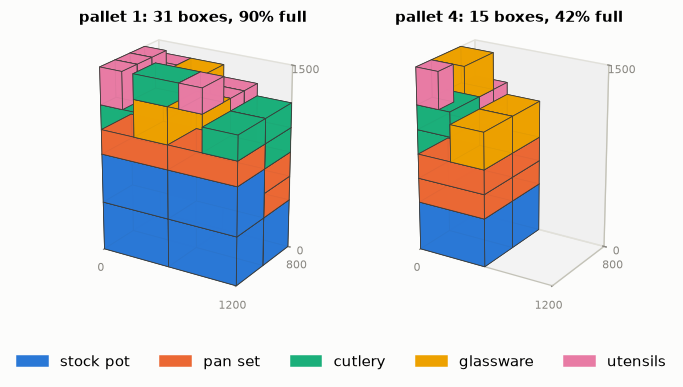

In [4]:
def box_faces(x, y, z, dx, dy, dz):
    corners = np.array([[x, y, z], [x + dx, y, z], [x + dx, y + dy, z], [x, y + dy, z],
                        [x, y, z + dz], [x + dx, y, z + dz], [x + dx, y + dy, z + dz], [x, y + dy, z + dz]])
    return [corners[face] for face in ([0, 1, 2, 3], [4, 5, 6, 7], [0, 1, 5, 4], [2, 3, 7, 6], [1, 2, 6, 5], [0, 3, 7, 4])]


def draw_container(ax, problem, index, color_of, title=None):
    """One container in 3D: its boxes, coloured by `color_of(item)`. The door is at the far end of x."""
    container = problem.containers[index]
    for item_index in container.placed_items:
        item = problem.items[item_index]
        faces = box_faces(item.x, item.y, item.z, item.placed_length, item.placed_width, item.placed_height)
        ax.add_collection3d(Poly3DCollection(faces, facecolor=color_of(item), edgecolor="#3a3a38", linewidth=0.5, alpha=0.95))
    ax.set(xlim=(0, container.length), ylim=(0, container.width), zlim=(0, container.height))
    ax.set_box_aspect((container.length, container.width, container.height))
    ax.set_xticks([0, container.length])
    ax.set_yticks([container.width])
    ax.set_zticks([0, container.height])
    ax.tick_params(labelsize=7, pad=-2)
    ax.view_init(elev=22, azim=-58)
    ax.set_title(title or f"{container.id}: {len(container.placed_items)} boxes, {container.fill_ratio:.0%} full", fontsize=10)


def draw_load(problem, color_of, handles, columns=None):
    used = [c for c, container in enumerate(problem.containers) if container.placed_items]
    columns = columns or len(used)
    fig = plt.figure(figsize=(3.4 * columns, 3.9))
    for position, index in enumerate(used):
        draw_container(fig.add_subplot(1, columns, position + 1, projection="3d"), problem, index, color_of)
    fig.legend(handles=handles, loc="lower center", ncol=len(handles), bbox_to_anchor=(0.5, -0.02))
    plt.show()


kind_handles = [Patch(color=color, label=name) for name, color in KIND_COLOR.items()]
draw_load(problem, lambda item: KIND_COLOR[kind_of(item)], kind_handles)

## 3. Check the result yourself

The answer is a position and a size per box, so it can be verified with no solver code. This checks,
from the numbers alone, that every box is inside its pallet, that no two boxes share space, that every
box off the floor rests on enough of the boxes under it, and that no pallet is overloaded.

In [5]:
def overlap(a_low, a_size, b_low, b_size):
    return max(0, min(a_low + a_size, b_low + b_size) - max(a_low, b_low))


def check(problem):
    outside, clashes, floating = [], [], []
    for container in problem.containers:
        boxes = [problem.items[i] for i in container.placed_items]
        for a in boxes:
            if a.x + a.placed_length > container.length or a.y + a.placed_width > container.width \
                    or a.z + a.placed_height > container.height:
                outside.append(a.id)
            supported = 0
            for b in boxes:
                if a is b:
                    continue
                dx = overlap(a.x, a.placed_length, b.x, b.placed_length)
                dy = overlap(a.y, a.placed_width, b.y, b.placed_width)
                dz = overlap(a.z, a.placed_height, b.z, b.placed_height)
                if dx and dy and dz:
                    clashes.append((a.id, b.id))
                if b.z + b.placed_height == a.z:
                    supported += dx * dy
            if a.z > 0 and supported < problem.min_support_ratio * a.placed_length * a.placed_width:
                floating.append(a.id)
    return outside, clashes, floating


outside, clashes, floating = check(problem)
print("every box on a pallet    :", problem.unplaced_items() == [])
print("boxes outside a pallet   :", outside)
print("boxes sharing space      :", clashes)
print("boxes without support    :", floating)
print("heaviest pallet          :", max(c.loaded_weight for c in problem.containers) / 1000, "kg of",
      problem.containers[0].max_weight / 1000)

every box on a pallet    : True
boxes outside a pallet   : []
boxes sharing space      : []
boxes without support    : []
heaviest pallet          : 229.5 kg of 500.0


## 4. Change the rules, not the solver

Every rule is a plugin. `list_constraints()` shows what ships with this use case, and the `constraints`
argument takes the list you want. Only listed constraints are scored. `weight` scales a rule,
`level="hard"` or `level="soft"` moves it between levels, `exponent` shapes large violations, and
`offset` / `clip` shift that shaping. Two of the eight are in the list at weight 0 and score only once
you give them a weight: `used_length_cost` and `load_balance_cost`.

`group_split_cost` keeps each shop on one pallet. It weighs 1 by default, the same as one pallet, so
a shop spread over two pallets is as bad as a third pallet; here the three shops fit two pallets
whole. The load is solved twice more: with a split weighing three pallets, and with the rule left out
of the list, where nothing keeps a shop together. The raw cost of every constraint, per container, is in
`constraint_costs`, so each plan can be read rule by rule whatever it was solved with.

In [6]:
for row in cl.constraint_info():
    print(f"{row.name:24s} {row.default_level}  weight {row.default_weight:g}")


def solve_with(picks):
    plan = make_problem()
    cl.solve(plan, time_limit_seconds=5, random_seed=1, constraints=picks)
    return plan


heavier = solve_with([rules.GroupSplitCost(weight=3) if spec.name == "group_split_cost" else spec
                      for spec in rules.get_constraints()])
without = solve_with([spec for spec in rules.get_constraints() if spec.name != "group_split_cost"])

print()
for label, plan in (("a split costs one pallet", problem), ("a split costs three", heavier), ("no rule", without)):
    print(f"{label:24s}: {plan.containers_used()} pallets, {shops_split(plan)} shops split, hard {plan.score.hard}")

unplaced_item_cost       hard  weight 1
container_weight_cost    hard  weight 1
stacking_load_cost       hard  weight 1
unloading_order_cost     hard  weight 1
used_container_cost      soft  weight 1
used_length_cost         soft  weight 0
load_balance_cost        soft  weight 0
group_split_cost         soft  weight 1



a split costs one pallet: 2 pallets, 0 shops split, hard 0
a split costs three     : 2 pallets, 0 shops split, hard 0
no rule                 : 2 pallets, 1 shops split, hard 0


Nothing else changed between the three: the same cartons, the same solver, another list of rules.
When the shops do not fit whole, whether a third pallet is worth an undivided delivery is a question
for the business, and the weight is where you answer it. (`shops_split` reads the raw cost off `constraint_costs`, which reports every
constraint of the catalog, whatever the plan was solved with.)

## 5. A van, in the order of its stops

The van leaves with parcels for three stops. Its cargo space is one container, the door is at
`x = length`, and each parcel's `unload_order` is the number of its stop. `unloading_order_cost`
counts the pairs where a parcel for a later stop stands between an earlier one and the door, or on top
of it; at hard 0 every stop finds its parcels free.

For comparison, the same parcels as a loader would take them straight off the route sheet: stop 1
first. `set_loading` writes a loading order by hand, and `calculate_score` places and scores it
without any search.

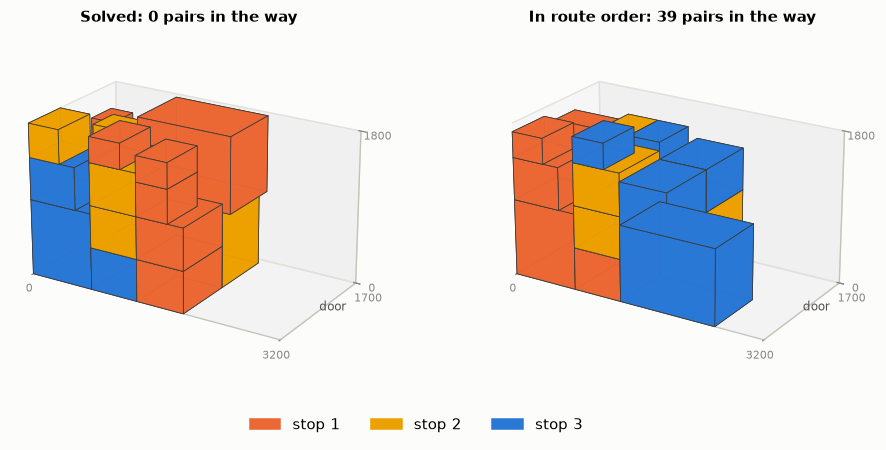

solved        : 0hard/-1soft  loading order by stop: [3, 3, 3, 3, 3, 3, 3, 2, 2, 2, 2, 2, 2, 2, 1, 1, 1, 1, 1, 1, 1]
in route order: -39hard/-1soft  (0 parcels found no place)


In [7]:
STOP_COLOR = {1: COLORS[1], 2: COLORS[3], 3: COLORS[0]}


def make_van():
    rng = np.random.default_rng(11)
    sizes = [(800, 600, 500), (600, 400, 400), (600, 400, 300), (400, 300, 300), (1200, 800, 900)]
    items = []
    for stop in (1, 2, 3):
        for i in range(7):
            length, width, height = sizes[int(rng.integers(0, 4))] if i else sizes[4]
            items.append(cl.Item(f"stop {stop} parcel {i + 1}", length, width, height,
                                 weight=int(length * width * height * 2e-4), rotations=cl.Rotation.UPRIGHT,
                                 unload_order=stop, group=f"stop {stop}"))
    return cl.ContainerLoadingProblem([cl.Container("van", 3200, 1700, 1800, max_weight=1_200_000)], items)


def blocked(problem):
    return int(sum(cl.constraint_costs(problem)["unloading_order_cost"]["costs"]))


van = make_van()
cl.solve(van, time_limit_seconds=5, random_seed=1)
route_order = make_van()
route_order.set_loading([list(range(len(route_order.items)))])   # stop 1 first, as the sheet lists them
cl.calculate_score(route_order)

fig = plt.figure(figsize=(10.4, 4.2))
for position, (plan, label) in enumerate(((van, "Solved"), (route_order, "In route order"))):
    ax = fig.add_subplot(1, 2, position + 1, projection="3d")
    draw_container(ax, plan, 0, lambda item: STOP_COLOR[item.unload_order],
                   title=f"{label}: {blocked(plan)} pairs in the way")
    ax.text(plan.containers[0].length, plan.containers[0].width / 2, 0, "door", color=INK, fontsize=8)
fig.legend(handles=[Patch(color=color, label=f"stop {stop}") for stop, color in STOP_COLOR.items()],
           loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.02))
plt.show()

print("solved        :", van.score, " loading order by stop:",
      [van.items[i].unload_order for i in van.containers[0].placed_items])
print("in route order:", route_order.score, f" ({len(route_order.unplaced_items())} parcels found no place)")

The loading order printed above goes from the last stop to the first: what leaves last is loaded
first and ends up at the closed end.

Giving `used_length_cost` a weight packs the load towards the closed end, which is how loading metres
are saved when the van is not full:

In [8]:
compact = make_van()
picks = [rules.UsedLengthCost(weight=0.001) if spec.name == "used_length_cost" else spec
         for spec in rules.get_constraints()]
cl.solve(compact, time_limit_seconds=5, random_seed=1, constraints=picks)
print(f"used length without the cost: {van.containers[0].used_length} mm, {blocked(van)} pairs in the way")
print(f"used length with the cost   : {compact.containers[0].used_length} mm, {blocked(compact)} pairs in the way")

used length without the cost: 2100 mm, 0 pairs in the way
used length with the cost   : 2000 mm, 0 pairs in the way


## 6. The cheapest cartons for an order

A web order of small items leaves in shipping cartons from a catalog. Each carton size has a price,
and the question is which cartons to take. List one container per carton you are willing to use, each
with its `cost`; the soft score is then minus the price of the cartons chosen.

Here the catalog has three sizes, and the order may use up to two of each.

In [9]:
CATALOG = {"S": (300, 200, 150, 0.6), "M": (400, 300, 200, 0.9), "L": (600, 400, 300, 1.7)}


def make_order(counts):
    cartons = [cl.Container(f"{size}-{copy}", length, width, height, cost=cost, max_weight=20_000)
               for size, (length, width, height, cost) in CATALOG.items() for copy in (1, 2)]
    goods = {"mug": (120, 100, 100, 350), "plate set": (280, 280, 80, 2400), "kettle": (250, 200, 220, 1300)}
    items = [cl.Item(f"{name} {i + 1}", *goods[name][:3], weight=goods[name][3]) for name, count in counts.items()
             for i in range(count)]
    return cl.ContainerLoadingProblem(cartons, items)


for counts in ({"mug": 6}, {"mug": 4, "plate set": 1}, {"mug": 6, "plate set": 2, "kettle": 1}):
    order = make_order(counts)
    cl.solve(order, time_limit_seconds=2, random_seed=1)
    chosen = Counter(container.id.split("-")[0] for container in order.containers if container.placed_items)
    print(f"{str(counts):48s} -> cartons {dict(chosen)}, price {-order.score.soft:.1f}, hard {order.score.hard}")

{'mug': 6}                                       -> cartons {'S': 1}, price 0.6, hard 0


{'mug': 4, 'plate set': 1}                       -> cartons {'M': 1}, price 0.9, hard 0


{'mug': 6, 'plate set': 2, 'kettle': 1}          -> cartons {'L': 1}, price 1.7, hard 0


Several orders can go into one request: give each order's items a `group`, and `group_split_cost`
keeps an order in one carton where it fits.

## 7. Late boxes, after the plan is made

Six more cartons arrive after the pallets of section 2 were planned. `with_initial_solution` takes a
solved model, or the same thing as a JSON dict, and starts the search from its loading orders. The
pydantic models in `optimaru.container_loading.models` mirror the problem; they are also the JSON the
optimaru API takes for this use case.

Boxes the old plan does not know are placed around it first, then the search goes on from there. With
`time_limit_seconds=0` that first step is all that happens: the old plan stays as it is and the late
boxes go where they fit. With a budget the search may move anything, since the score does not reward
keeping a plan stable. To see how much moved, count the pairs of boxes that shared a pallet in the
old plan and still do, which does not depend on how the pallets are numbered.

In [10]:
today = ContainerLoadingProblemModel.from_core(problem)
late = [cl.Item(f"late pan set {i + 1}", 600, 400, 200, weight=9000, group=f"shop {i % 3 + 1}") for i in range(6)]
updated = ContainerLoadingProblemModel.from_core(
    cl.ContainerLoadingProblem(problem.containers, [*problem.items, *late]))

placed_around = cl.solve(cl.with_initial_solution(updated, today), time_limit_seconds=0)
warm = cl.solve(cl.with_initial_solution(updated, today), time_limit_seconds=5, random_seed=2)
cold = cl.solve(cl.with_initial_solution(updated, {"containers": []}), time_limit_seconds=5, random_seed=2)

def pallet_mates(solved, ids):
    """The pairs of these boxes that stand on the same pallet."""
    where = {item.id: item.container for item in solved.items if item.id in ids}
    return {(a, b) for a in where for b in where if a < b and where[a] == where[b]}


old_ids = {item.id for item in today.items}
before = pallet_mates(today, old_ids)
print(f"pairs sharing a pallet in the old plan: {len(before)}")
for label, plan in (("placed around it", placed_around), ("from the old plan", warm), ("from scratch", cold)):
    print(f"{label:17s}: score {plan.score_hard} / {plan.score_soft}, {plan.containers_used} pallets, "
          f"{len(before & pallet_mates(plan, old_ids))} pairs kept")
print(warm.items[-1].model_dump_json(exclude_none=True))

pairs sharing a pallet in the old plan: 570
placed around it : score 0 / -4.0, 2 pallets, 570 pairs kept
from the old plan: score 0 / -3.0, 3 pallets, 330 pairs kept
from scratch     : score 0 / -3.0, 2 pallets, 486 pairs kept
{"id":"late pan set 6","length":600,"width":400,"height":200,"weight":9000,"rotations":"all","group":"shop 3","container":"pallet 3","sequence":6,"x":0,"y":0,"z":800,"placed_length":600,"placed_width":400,"placed_height":200}


## Next steps

- `docs/use-cases/container-loading/README.md` has the JSON model field by field, the exact meaning
  of every constraint, how the placement rule works, and the solver settings (`stop.time_limit_seconds`,
  `stop.step_limit`, `custom_moves.empty_container`, `custom_moves.switch_container`, `custom_moves.stop_order`, the move weights,
  the ruin-and-recreate knobs).
- For packing by weight alone, into identical bins, see `bin-packing.ipynb`.
- For the route whose stop order the van of section 5 follows, see `vehicle-routing.ipynb`.